# P10: Hydraulic System Signal Processing and Diagnostic Risk Evaluation

**Project:** Integrating data engineering, digital signal processing, and diagnostic error analysis for internal pump leakage classification on the **UCI Condition Monitoring of Hydraulic Systems** dataset.

**Notebook scope and workflow:**
- **E1:** Data integrity audit, sampling rates, target distribution, and condition-matched sensor waveforms.
- **E2:** Cutoff-matched FIR and first-order IIR filter design per sensor, full-cycle traces, and **transient step zoom**.
- **E3:** Z-transform transfer functions, frequency responses, impulse responses, and **digital filter** stability.
- **E4:** Raw, FIR, and IIR classification using a grouped holdout split, followed by **5-fold GroupKFold cross-validation**.
- **E4b:** Ablation study across sensors (`PS1` vs. `FS1`) and feature domains (time-domain vs. frequency-domain).
- **E4c:** Filter window sensitivity analysis across **0.3, 0.5, and 1.0 s** smoothing durations on identical folds.
- **E5 (optional):** Digital downsampling and anti-aliasing illustration.
- **E6 to E10:** Pooled out-of-fold (OOF) confusion matrices, severe-leakage miss analysis, hypothetical cost-matrix evaluation, optional permutation importance, and methodological limitations.

**Research question:** Does causal low-pass filtering improve pump leakage classification across unseen auxiliary component states, or does smoothing remove useful diagnostic information? The answer is determined empirically from grouped evaluation rather than assumed upfront.

**Scope note:** The dataset provides digitized sensor recordings rather than raw analog voltages. The transfer function `H(z)` describes the **designed digital filter**, not the physical transfer function of the hydraulic rig. Grouping by auxiliary component conditions does not replace validation on a separate physical machine.

**References:** [UCI Dataset](https://doi.org/10.24432/C5CW21), [Helwig et al. (2015)](https://doi.org/10.1109/I2MTC.2015.7151267), [SciPy Signal Documentation](https://docs.scipy.org/doc/scipy/reference/signal.html).

## Setup (VS Code / Jupyter)

Place `PS1.txt`, `FS1.txt`, and `profile.txt` in the `data/` folder (or in the same directory as this notebook). `documentation.txt` is recommended as a reference guide but is not read by the code.

**Dependencies:** `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`, `ipykernel` / `jupyter`.

Each row represents one 60-second operating cycle. `PS1` (100 Hz) and `FS1` (10 Hz) are filtered and summarized **independently** on their native time axes and then joined as cycle-level features. Forced upsampling of `FS1` to 100 Hz is not required. Sufficient available RAM (~500 MB) is needed because `PS1.txt` contains 2,205 x 6,000 samples.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import signal
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, classification_report, recall_score,
    ConfusionMatrixDisplay
)
from IPython.display import display

SEED = 42
STABLE_ONLY = True          # True = stable cycles only (stable_flag == 0); False = all 2,205 cycles
WINDOW_SECONDS = 0.50      # FIR moving average window duration in seconds
TEST_FRACTION = 0.20       # Fraction of configuration groups held out in initial split
RUN_E5 = False              # Optional downsampling illustration
SAVE_RESULTS = True

# Locate dataset files in ./data, ../data, current directory, or parent directory
candidates = [Path.cwd() / "data", Path.cwd().parent / "data", Path.cwd(), Path.cwd().parent]
needed = {'PS1.txt', 'FS1.txt', 'profile.txt'}
DATA_DIR = next((p for p in candidates if p.is_dir() and all((p / f).exists() for f in needed)), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Dataset files not found. Place PS1.txt, FS1.txt, and profile.txt in data/ or the notebook directory.'
    )
OUTPUT_DIR = (Path.cwd().parent / 'results') if Path.cwd().name == 'notebooks' else (Path.cwd() / 'results')
print('Data directory:', DATA_DIR.name or './data')
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__, '| SciPy:', scipy.__version__)

Data directory: data
Python: 3.11.8 | NumPy: 2.3.5 | SciPy: 1.16.3


## E1: Data Audit, Target Distribution, and Sampling Rates

Dataset structure from the UCI documentation:

| File | Sensor / Description | Unit | Sampling Rate | Columns per Cycle |
|---|---|---|---:|---:|
| `PS1.txt` | Pressure sensor 1 | bar | 100 Hz | 6,000 |
| `FS1.txt` | Volume flow sensor 1 | L/min | 10 Hz | 600 |
| `profile.txt` | Component condition labels | 5 integer columns | Cycle-level | 5 |

Columns in `profile.txt` in order: `cooler`, `valve`, `pump_leakage`, `accumulator`, `stable_flag`. **`stable_flag = 0` indicates stable operating conditions; `1` indicates that static conditions might not yet have been reached.** Zero readings in `FS1` may reflect low-flow operating periods and are not automatically treated as missing values.

In [2]:
profile_cols = ['cooler', 'valve', 'pump_leakage', 'accumulator', 'stable_flag']
profile = pd.read_csv(DATA_DIR / 'profile.txt', sep=r'\s+', header=None, names=profile_cols)
ps1 = np.loadtxt(DATA_DIR / 'PS1.txt', dtype=np.float32)
fs1 = np.loadtxt(DATA_DIR / 'FS1.txt', dtype=np.float32)

assert profile.shape == (2205, 5), f'Unexpected profile shape: {profile.shape}'
assert ps1.shape == (2205, 6000), f'Unexpected PS1 shape: {ps1.shape}'
assert fs1.shape == (2205, 600), f'Unexpected FS1 shape: {fs1.shape}'
assert profile['pump_leakage'].isin([0, 1, 2]).all()
assert profile['stable_flag'].isin([0, 1]).all()
profile.insert(0, 'cycle_id', np.arange(len(profile)))

sample_rates = {'PS1': 100, 'FS1': 10}
signals = {'PS1': ps1, 'FS1': fs1}
qc_rows = []
for sensor, arr in signals.items():
    qc_rows.append({
        'sensor': sensor, 'siklus': arr.shape[0], 'sampel/siklus': arr.shape[1],
        'fs (Hz)': sample_rates[sensor], 'durasi (s)': arr.shape[1] / sample_rates[sensor],
        'minimum': float(np.min(arr)), 'maksimum': float(np.max(arr)),
        'NaN': int(np.isnan(arr).sum()), 'Inf': int(np.isinf(arr).sum()),
        'nol (proporsi)': float(np.mean(arr == 0)),
    })
qc = pd.DataFrame(qc_rows)
display(qc)
assert all(np.isfinite(arr).all() for arr in signals.values()), 'Non-finite values detected in sensor arrays'

print('Target distribution across all cycles (by stable_flag):')
display(pd.crosstab(profile['pump_leakage'], profile['stable_flag'], margins=True))

,sensor,siklus,sampel/siklus,fs (Hz),durasi (s),minimum,maksimum,NaN,Inf,nol (proporsi)
0,PS1,2205,6000,100,60.0,133.130005,191.919998,0,0,0.000000
1,FS1,2205,600,10,60.0,0.000000,20.479000,0,0,0.056473


Target distribution across all cycles (by stable_flag):


stable_flag,0,1,All
pump_leakage,,,
0,489,732,1221
1,480,12,492
2,480,12,492
All,1449,756,2205


Selected cycles for analysis: 1449 | STABLE_ONLY = True


,count
pump_leakage,
0,489
1,480
2,480


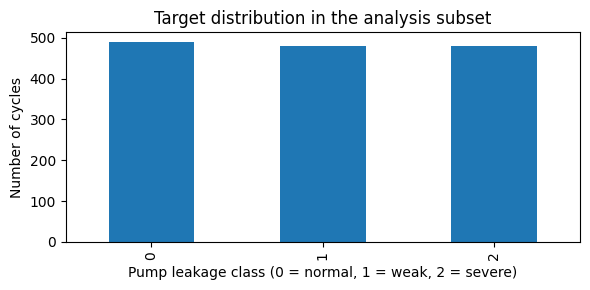

In [3]:
# Select stable cycles for the primary analysis without deleting rows from the raw arrays.
selected_idx = np.flatnonzero(profile['stable_flag'].to_numpy() == 0) if STABLE_ONLY else np.arange(len(profile))
meta = profile.iloc[selected_idx].copy().reset_index(drop=True)
assert len(meta) > 0
print('Selected cycles for analysis:', len(meta), '| STABLE_ONLY =', STABLE_ONLY)
display(meta['pump_leakage'].value_counts().sort_index().rename('count').to_frame())

fig, ax = plt.subplots(figsize=(6, 3))
meta['pump_leakage'].value_counts().sort_index().plot.bar(ax=ax)
ax.set(xlabel='Pump leakage class (0 = normal, 1 = weak, 2 = severe)', ylabel='Number of cycles',
       title='Target distribution in the analysis subset')
plt.tight_layout(); plt.show()

### Selecting Condition-Matched Cycles for Visual Comparison

We select three cycles that share identical **cooler, valve, and accumulator** states while differing in `pump_leakage` class (`0`, `1`, `2`). Because multiple component degradations can interact, this plot serves as a condition-matched visual illustration rather than standalone causal proof.

Matched auxiliary component state: {'cooler': np.int64(100), 'valve': np.int64(100), 'accumulator': np.int64(90)}


,cycle_id,cooler,valve,accumulator,pump_leakage,stable_flag
1434,2190,100,100,90,0,0
1396,2151,100,100,90,1,0
1351,2105,100,100,90,2,0


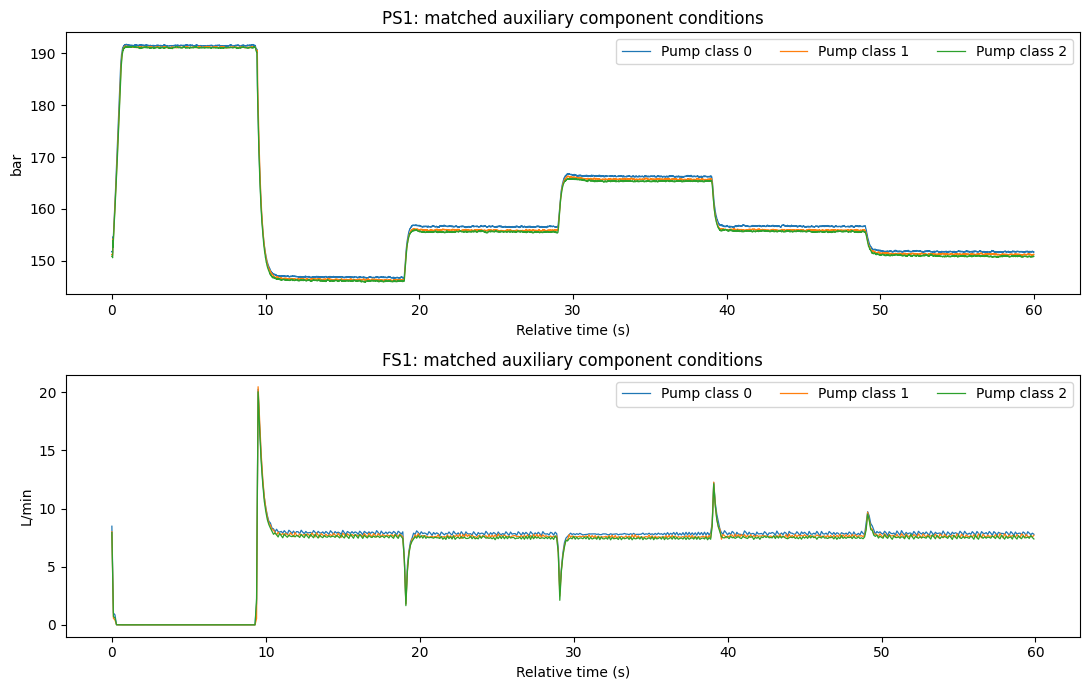

In [4]:
confound_cols = ['cooler', 'valve', 'accumulator']
matching = (
    meta.groupby(confound_cols)['pump_leakage']
    .agg(n_classes='nunique', n_cycles='size')
    .query('n_classes == 3')
    .sort_values('n_cycles', ascending=False)
)
if matching.empty:
    raise ValueError('No cooler-valve-accumulator combination contains all three pump leakage classes')
combo = matching.index[0]
mask = np.logical_and.reduce([meta[c].to_numpy() == v for c, v in zip(confound_cols, combo)])
matched = meta.loc[mask].sort_values('pump_leakage').drop_duplicates('pump_leakage')
matched_original_ids = matched['cycle_id'].to_numpy(dtype=int)
print('Matched auxiliary component state:', dict(zip(confound_cols, combo)))
display(matched[['cycle_id', *confound_cols, 'pump_leakage', 'stable_flag']])

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, (sensor, unit) in zip(axes, [('PS1','bar'), ('FS1','L/min')]):
    fs = sample_rates[sensor]
    t = np.arange(signals[sensor].shape[1]) / fs
    for cid, pump in zip(matched_original_ids, matched['pump_leakage']):
        ax.plot(t, signals[sensor][cid], lw=0.9, label=f'Pump class {pump}')
    ax.set(title=f'{sensor}: matched auxiliary component conditions', xlabel='Relative time (s)', ylabel=unit)
    ax.legend(ncol=3)
plt.tight_layout(); plt.show()

## E2: FIR and IIR Digital Filtering on Sensor Signals

We design causal low-pass digital filters **independently for each sensor** according to its sampling rate:

**FIR moving average:**

\[
y[n]=\frac{1}{L}\sum_{k=0}^{L-1}x[n-k],\qquad H_{FIR}(z)=\frac{1}{L}\sum_{k=0}^{L-1}z^{-k}
\]

**First-order IIR exponential smoothing:**

\[
y[n]=(1-\alpha)x[n]+\alpha y[n-1],\quad H_{IIR}(z)=\frac{1-\alpha}{1-\alpha z^{-1}}
\]

To compare filter architectures fairly rather than using arbitrary parameters, the feedback coefficient `alpha` is solved analytically so that the IIR filter matches the **-3 dB cutoff frequency** of the FIR filter on the same sensor, where `L = max(3, round(fs * 0.50 s))`.

**Boundary initialization:** Each cycle is initialized at the steady state of its first sample (`lfilter_zi` scaled by `x[0]`) to avoid an artificial zero-startup jump at `t = 0 s`. Cycles are filtered independently **without carrying filter state across cycle boundaries**. Because pre-cycle history is unavailable in the dataset, constant-level initialization prior to `t = 0 s` remains a modeling assumption.

In [5]:
def design_filters(fs: int, window_seconds: float = WINDOW_SECONDS):
    L = max(3, int(round(fs * window_seconds)))
    fir_b = np.ones(L, dtype=np.float64) / L
    fir_a = np.array([1.0])
    f, H = signal.freqz(fir_b, fir_a, worN=32768, fs=fs)
    response = np.abs(H)
    cutoff_i = np.flatnonzero(response <= 1/np.sqrt(2))
    if len(cutoff_i) == 0:
        raise ValueError('FIR filter does not have a valid -3 dB cutoff point')
    cutoff = float(f[cutoff_i[0]])
    omega = 2*np.pi*cutoff/fs
    t = 2-np.cos(omega)
    alpha = float(t-np.sqrt(t*t-1))  # stable first-order IIR root matched to the FIR -3 dB cutoff
    assert 0 < alpha < 1
    iir_b = np.array([1-alpha])
    iir_a = np.array([1.0, -alpha])
    return {'FIR':(fir_b, fir_a), 'IIR':(iir_b, iir_a),
            'L':L, 'alpha':alpha, 'fc_Hz':cutoff}

filters = {sensor: design_filters(fs) for sensor, fs in sample_rates.items()}
display(pd.DataFrame([{
    'sensor':name, 'fs (Hz)':sample_rates[name], 'FIR L':d['L'],
    '-3dB (Hz)':round(d['fc_Hz'],4), 'IIR alpha':round(d['alpha'],6),
    'IIR pole':round(d['alpha'],6)
} for name,d in filters.items()]))


def filter_cycles(arr: np.ndarray, b, a):
    """Apply a causal digital filter along the time axis, initialized at each cycle's first sample."""
    arr = np.asarray(arr, dtype=np.float64)
    zi_base = signal.lfilter_zi(b, a)
    zi = np.broadcast_to(zi_base, (len(arr), len(zi_base))).copy() * arr[:, :1]
    y, _ = signal.lfilter(b, a, arr, axis=1, zi=zi)
    return y.astype(np.float32)

# Sanity check on filter initialization: a constant input signal must remain constant.
for s, cfg in filters.items():
    for mode in ['FIR','IIR']:
        b,a=cfg[mode]
        test = filter_cycles(np.ones((2,30), dtype=np.float32)*7, b, a)
        assert np.allclose(test,7,atol=1e-5), (s,mode)
print('Constant-signal initialization check: PASSED')

,sensor,fs (Hz),FIR L,-3dB (Hz),IIR alpha,IIR pole
0,PS1,100,50,0.8865,0.945834,0.945834
1,FS1,10,5,0.9016,0.575832,0.575832


Constant-signal initialization check: PASSED


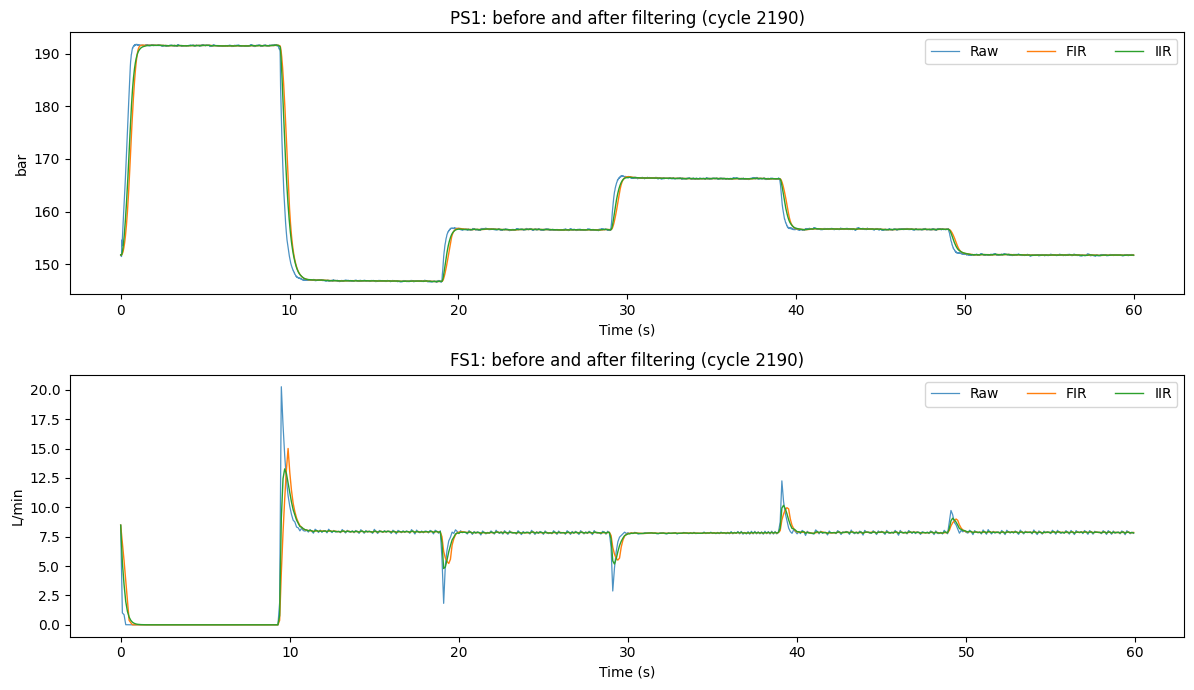

In [6]:
# Overlay Raw, FIR, and IIR traces across the full 60-second operating cycle.
example_cid = int(matched_original_ids[0])
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (name, unit) in zip(axes, [('PS1','bar'), ('FS1','L/min')]):
    x = signals[name][example_cid:example_cid+1]
    fs = sample_rates[name]
    t = np.arange(x.shape[1])/fs
    ax.plot(t, x[0], lw=0.9, alpha=0.8, label='Raw')
    for mode in ['FIR','IIR']:
        b,a = filters[name][mode]
        ax.plot(t, filter_cycles(x,b,a)[0], lw=1.0, label=mode)
    ax.set(title=f'{name}: before and after filtering (cycle {example_cid})',
           xlabel='Time (s)', ylabel=unit)
    ax.legend(ncol=3)
plt.tight_layout(); plt.show()

### E2b: Zoomed View Around the Sharpest Transient Step

On a full 60-second axis, the three curves largely overlap. Zooming in around the largest sample-to-sample step change reveals differences in response lag and step smoothing. The zoom window is centered **purely from the raw signal derivative**, without referencing target labels or model predictions. Visual smoothness alone does not imply better classification performance.

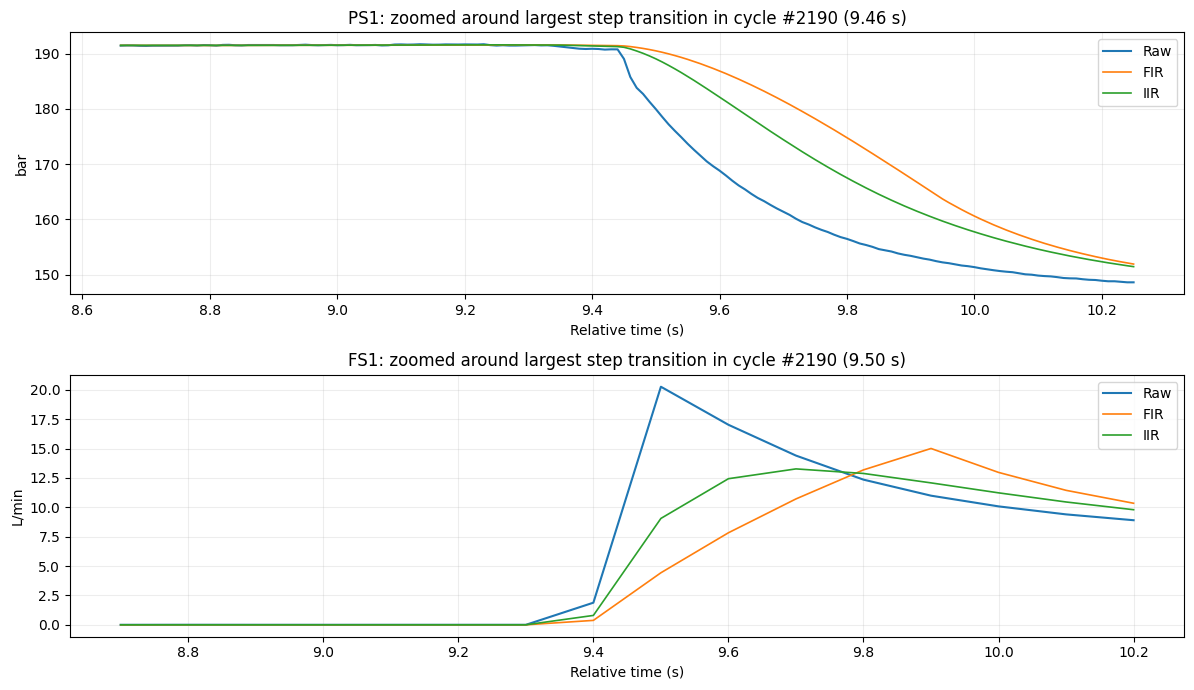

,sensor,mode,rms_diff_raw_filter
0,PS1,FIR,2.2728
1,PS1,IIR,1.5487
2,FS1,FIR,0.9509
3,FS1,IIR,0.6046


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
zoom_rows = []
for ax, (sensor, unit) in zip(axes, [('PS1', 'bar'), ('FS1', 'L/min')]):
    fs = sample_rates[sensor]
    raw = signals[sensor][example_cid].astype(np.float64)
    n = len(raw)
    center = int(np.argmax(np.abs(np.diff(raw)))) + 1
    radius = max(3, int(round(fs * 0.8)))
    lo, hi = max(0, center-radius), min(n, center+radius)
    t = np.arange(lo, hi) / fs
    ax.plot(t, raw[lo:hi], label='Raw', lw=1.5)
    for mode in ['FIR', 'IIR']:
        b, a = filters[sensor][mode]
        processed = filter_cycles(raw[None, :], b, a)[0].astype(np.float64)
        ax.plot(t, processed[lo:hi], label=mode, lw=1.2)
        zoom_rows.append({'sensor': sensor, 'mode': mode,
                          'rms_diff_raw_filter': float(np.sqrt(np.mean((processed-raw)**2)))})
    ax.set(title=f'{sensor}: zoomed around largest step transition in cycle #{example_cid} ({center/fs:.2f} s)',
           xlabel='Relative time (s)', ylabel=unit)
    ax.grid(alpha=0.22); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(zoom_rows).round(4))

## E3: Z-Transform and Digital Filter Frequency Response

For each **designed digital filter**, the discrete-time transfer function is:

\[
H(z)=\frac{\sum_{k=0}^{M}b_k z^{-k}}{\sum_{k=0}^{N}a_k z^{-k}}
\]

The frequency response is evaluated on the unit circle: \(H(e^{j\omega})=H(z)|_{z=e^{j\omega}}\).

- **Magnitude response:** Shows which frequency components pass and which are attenuated.
- **Phase response:** Shows phase shift and group delay across frequency components.
- **IIR pole location:** Single real pole at \(z=\alpha\); because \(0<\alpha<1\), the causal first-order IIR filter is BIBO stable.
- **Impulse response:** \(h_{FIR}[n]\) has finite support of length \(L\); \(h_{IIR}[n]=(1-\alpha)\alpha^n u[n]\) decays exponentially.

**Note:** These transfer functions characterize the digital preprocessing filters, not the physical fluid-mechanical transfer function of the hydraulic rig.

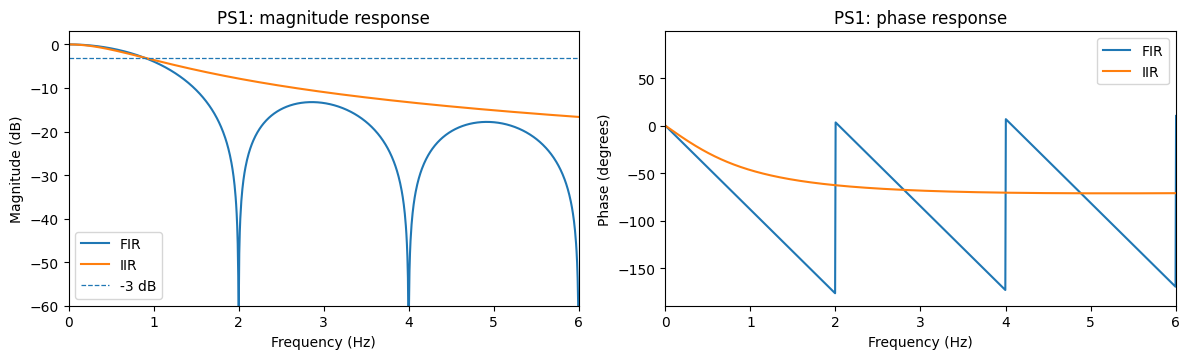

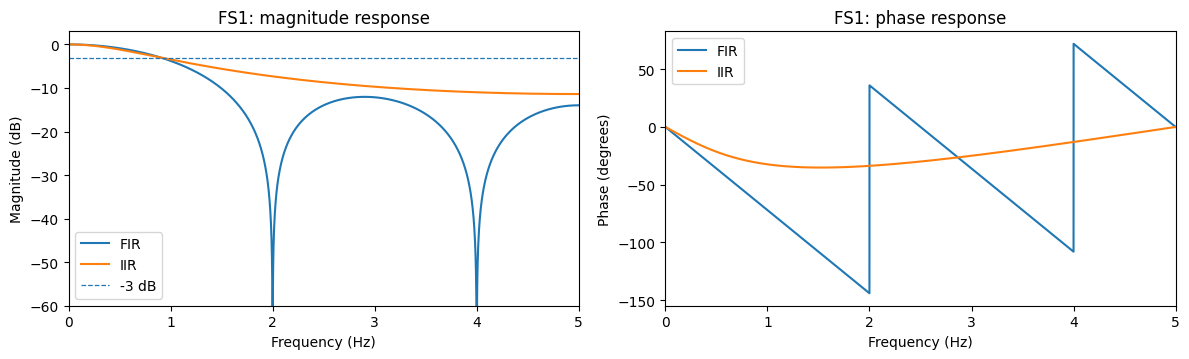

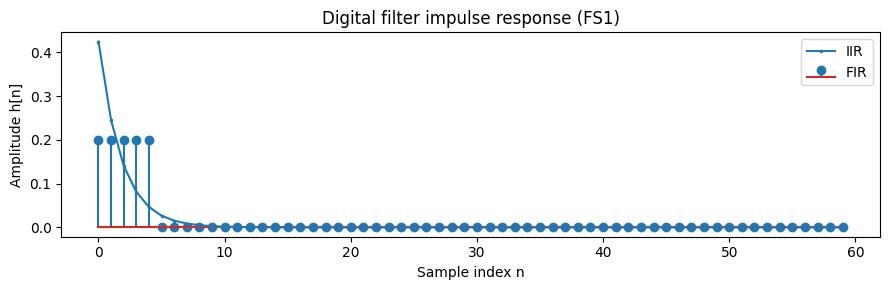

In [8]:
for name,cfg in filters.items():
    fs=sample_rates[name]
    fig, axs = plt.subplots(1,2,figsize=(12,3.7))
    for mode in ['FIR','IIR']:
        b,a=cfg[mode]
        freq,H=signal.freqz(b,a,fs=fs,worN=8192)
        mag=20*np.log10(np.maximum(np.abs(H),1e-9))
        phase=np.unwrap(np.angle(H))*180/np.pi
        axs[0].plot(freq,mag,label=mode)
        axs[1].plot(freq,phase,label=mode)
    axs[0].axhline(-3.0103,ls='--',lw=0.9,label='-3 dB')
    axs[0].set(xlabel='Frequency (Hz)',ylabel='Magnitude (dB)',title=f'{name}: magnitude response',ylim=(-60,3))
    axs[1].set(xlabel='Frequency (Hz)',ylabel='Phase (degrees)',title=f'{name}: phase response')
    for ax in axs:
        ax.set_xlim(0,min(6,fs/2))
        ax.legend()
    plt.tight_layout();plt.show()

# Digital filter impulse response on FS1 (visual illustration starting at n = 0).
cfg=filters['FS1']
n=np.arange(60)
h_fir=np.zeros_like(n,dtype=float)
h_fir[:cfg['L']]=1/cfg['L']
h_iir=(1-cfg['alpha'])*cfg['alpha']**n
plt.figure(figsize=(9,3))
plt.stem(n,h_fir,label='FIR')
plt.plot(n,h_iir,label='IIR',marker='.',markersize=3)
plt.title('Digital filter impulse response (FS1)')
plt.xlabel('Sample index n');plt.ylabel('Amplitude h[n]');plt.legend();plt.tight_layout();plt.show()

## E4: Cycle-Level Feature Extraction and Pump Leakage Classification

**The unit of observation is one 60-second operating cycle, not an individual time sample.** Features are computed separately for `PS1` and `FS1` and concatenated into **one 14-feature vector per cycle**.

Identical feature definitions are applied to **Raw**, **FIR**, and **IIR** signals: cycle mean, standard deviation, RMS, peak-to-peak range, RMS of first differences, spectral centroid, and fraction of spectral power at or above \(2\text{ Hz}\). Welch power spectral density is computed with constant mean detrending; these spectral quantities act as descriptive summary features rather than validated physical fault-frequency signatures.

**Validation design:** A Random Forest classifier with fixed hyperparameters is first tested on an exploratory 80/20 grouped holdout split keyed on `cooler|valve|accumulator` states, followed by **5-fold GroupKFold** cross-validation as the primary evaluation. No `cooler|valve|accumulator` configuration group is shared between training and test sets within any fold. All signal modes are evaluated on the exact same splits.

**Reported metrics:** Macro F1, balanced accuracy, per-class recall, and confusion matrices. The single holdout split is **exploratory**; model comparisons rely on the 5-fold grouped evaluation and pooled out-of-fold error analysis.

Raw (1449, 14) finite= True


FIR (1449, 14) finite= True


IIR (1449, 14) finite= True


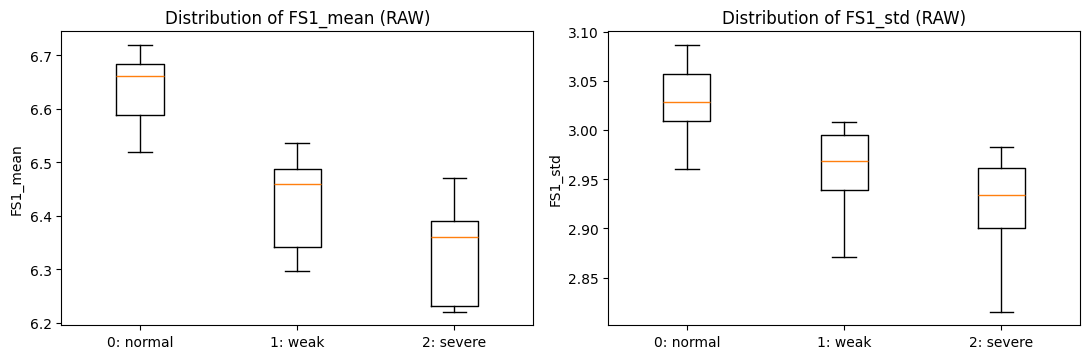

In [9]:
def extract_cycle_features(x: np.ndarray, fs: int, prefix: str) -> pd.DataFrame:
    """Extract 7 time- and frequency-domain summary features per cycle; the >= 2 Hz band is below Nyquist on both sensors."""
    x=np.asarray(x,dtype=np.float32)
    dx=np.diff(x.astype(np.float64),axis=1)
    f,psd=signal.welch(x,fs=fs,axis=1,nperseg=min(4*fs,x.shape[1]),
                       noverlap=min(2*fs,x.shape[1]//2),detrend='constant')
    nonzero = f>0
    spectral_power = psd[:, nonzero]
    freq = f[nonzero]
    denom=np.sum(spectral_power,axis=1) + 1e-12
    out=pd.DataFrame({
        f'{prefix}_mean':np.mean(x,axis=1),
        f'{prefix}_std':np.std(x,axis=1),
        f'{prefix}_rms':np.sqrt(np.mean(x.astype(np.float64)**2,axis=1)),
        f'{prefix}_p2p':np.ptp(x,axis=1),
        f'{prefix}_diff_rms':np.sqrt(np.mean(dx**2,axis=1)),
        f'{prefix}_spectral_centroid_Hz': (spectral_power*freq).sum(axis=1)/denom,
        f'{prefix}_power_frac_ge2Hz':spectral_power[:,freq>=2.0].sum(axis=1)/denom,
    })
    if not np.isfinite(out.to_numpy()).all():
        raise ValueError(f'Non-finite values found in extracted features for {prefix}')
    return out

features_by_mode={}
for mode in ['Raw','FIR','IIR']:
    feature_parts=[]
    for s in ['PS1','FS1']:
        x=signals[s][selected_idx]
        if mode!='Raw':
            b,a=filters[s][mode]
            x=filter_cycles(x,b,a)
        feature_parts.append(extract_cycle_features(x,sample_rates[s],s))
        del x
    features_by_mode[mode]=pd.concat(feature_parts,axis=1)
    print(mode,features_by_mode[mode].shape, 'finite=', np.isfinite(features_by_mode[mode].to_numpy()).all())

# Exploratory boxplot of unfiltered flow level and dispersion across pump leakage classes.
fig,axes=plt.subplots(1,2,figsize=(11,3.7))
for ax, feature in zip(axes,['FS1_mean','FS1_std']):
    data=[features_by_mode['Raw'].loc[meta.pump_leakage==v,feature] for v in [0,1,2]]
    ax.boxplot(data, tick_labels=['0: normal','1: weak','2: severe'],showfliers=False)
    ax.set(title=f'Distribution of {feature} (RAW)',ylabel=feature)
plt.tight_layout();plt.show()

Grouped holdout split: 1149 train / 300 test cycles
Unique configuration groups: 38 train / 10 test


,train,test
0,389,100
1,380,100
2,380,100


,macro_f1,balanced_accuracy
perlakuan,,
FIR,0.9533,0.9533
IIR,0.9633,0.9633
Raw,0.9733,0.9733


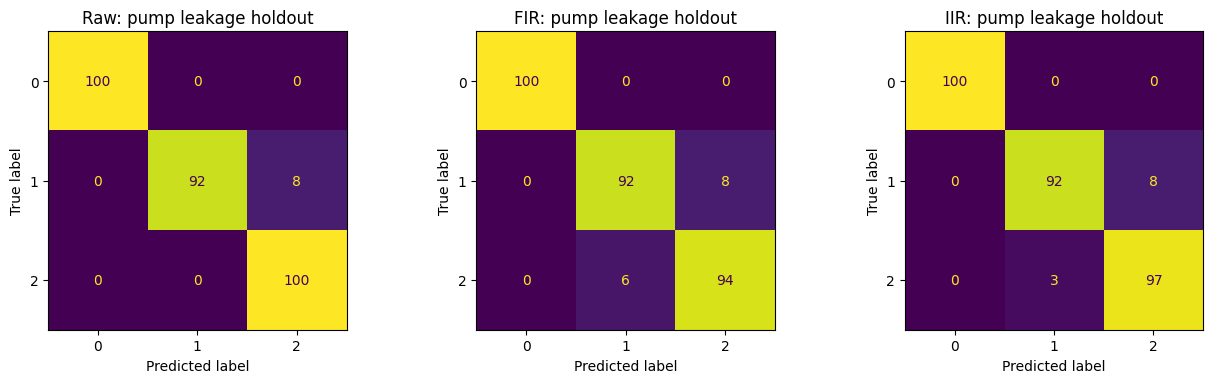

--- Raw ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      0.92      0.96       100
           2       0.93      1.00      0.96       100

    accuracy                           0.97       300
   macro avg       0.98      0.97      0.97       300
weighted avg       0.98      0.97      0.97       300

--- FIR ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       0.94      0.92      0.93       100
           2       0.92      0.94      0.93       100

    accuracy                           0.95       300
   macro avg       0.95      0.95      0.95       300
weighted avg       0.95      0.95      0.95       300

--- IIR ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       0.97      0.92      0.94       100
           2       0.92      0.97      

In [10]:
# Grouping key constructed from auxiliary component states (excluding the target pump leakage label)
groups=meta[confound_cols].astype(str).agg('|'.join,axis=1).to_numpy()
y=meta['pump_leakage'].to_numpy().astype(int)
classes=np.array([0,1,2])
splitter=GroupShuffleSplit(n_splits=1,test_size=TEST_FRACTION,random_state=SEED)
train_idx,test_idx=next(splitter.split(features_by_mode['Raw'],y,groups=groups))
assert set(groups[train_idx]).isdisjoint(set(groups[test_idx]))
assert set(np.unique(y[train_idx])) == set(classes)
assert set(np.unique(y[test_idx])) == set(classes)
print('Grouped holdout split:',len(train_idx),'train /',len(test_idx),'test cycles')
print('Unique configuration groups:',len(np.unique(groups[train_idx])),'train /',len(np.unique(groups[test_idx])),'test')
display(pd.DataFrame({'train':pd.Series(y[train_idx]).value_counts(),
                      'test':pd.Series(y[test_idx]).value_counts()}).fillna(0).astype(int).sort_index())

metrics=[]
preds={}
for mode, feat in features_by_mode.items():
    clf=RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                               class_weight='balanced_subsample', random_state=SEED,n_jobs=-1)
    clf.fit(feat.iloc[train_idx],y[train_idx])
    pred=clf.predict(feat.iloc[test_idx]);preds[mode]=pred
    metrics.append({'perlakuan':mode,
                    'macro_f1':f1_score(y[test_idx],pred,average='macro',zero_division=0),
                    'balanced_accuracy':balanced_accuracy_score(y[test_idx],pred)})

metrics_df=pd.DataFrame(metrics).set_index('perlakuan').sort_index()
display(metrics_df.round(4))
fig,axes=plt.subplots(1,3,figsize=(13,3.9))
for ax,mode in zip(axes,['Raw','FIR','IIR']):
    ConfusionMatrixDisplay.from_predictions(y[test_idx],preds[mode],labels=classes,
                 ax=ax,colorbar=False,values_format='d')
    ax.set(title=f'{mode}: pump leakage holdout')
plt.tight_layout();plt.show()
for mode in ['Raw','FIR','IIR']:
    print(f'--- {mode} ---')
    print(classification_report(y[test_idx],preds[mode],labels=classes,zero_division=0))

## E4a: 5-Fold GroupKFold Cross-Validation

A single holdout split depends on which 10 configuration groups fall into the test partition. We run 5-fold `GroupKFold` cross-validation to check how the ranking between Raw, FIR, and IIR behaves across all 48 configuration groups:

- **Grouping variable:** `cooler|valve|accumulator` composite state. Each configuration group appears in either the training set or the test set of a given fold, never both.
- **Target:** `pump_leakage` across three classes (`0`, `1`, `2`). All signal modes, feature subsets, and filter windows use the **exact same fold assignments**.
- **Fixed classifier:** Random Forest hyperparameters remain fixed across all comparisons rather than tuned on the evaluation folds.
- **Reporting:** Mean and fold standard deviation (SD), alongside paired per-fold differences relative to Raw. Because the five training folds overlap on a single test rig, differences are reported descriptively without formal statistical significance claims.

5-FOLD GROUP CV RESULTS (mean and fold SD; descriptive comparison without significance claims):


macro_f1         balanced_accuracy         recall_0         recall_1  \
         mean     std              mean     std     mean     std     mean   
mode                                                                        
FIR    0.9454  0.0360            0.9456  0.0356   0.9960  0.0055   0.9264   
IIR    0.9545  0.0323            0.9547  0.0321   0.9960  0.0055   0.9396   
Raw    0.9462  0.0394            0.9465  0.0390   0.9915  0.0092   0.9456   

             recall_2          
         std     mean     std  
mode                           
FIR   0.0439   0.9144  0.0847  
IIR   0.0528   0.9287  0.0712  
Raw   0.0427   0.9024  0.1004

Macro F1 by fold:


mode,Raw,FIR,IIR
fold,,,
1,0.9632,0.9521,0.9669
2,0.8823,0.8925,0.9092
3,0.9397,0.9331,0.9364
4,0.9867,0.9900,0.9933
5,0.9593,0.9592,0.9666


Paired Macro F1 difference vs. Raw:


,FIR - Raw,IIR - Raw
fold,,
1,-0.0111,0.0037
2,0.0101,0.0269
3,-0.0066,-0.0033
4,0.0033,0.0067
5,-0.0001,0.0074


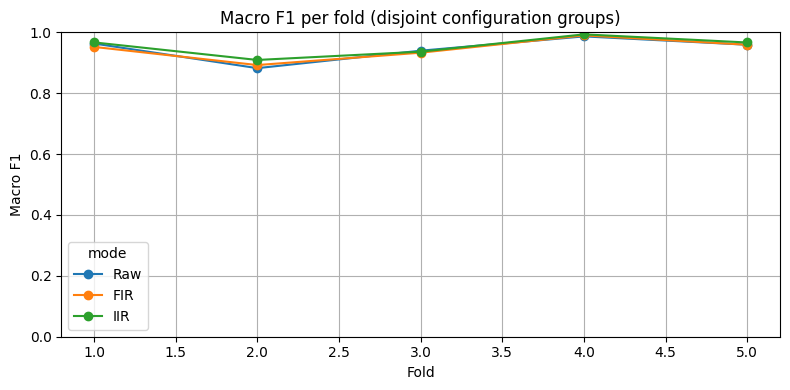

In [11]:
# Lock 5-fold GroupKFold indices for all subsequent comparative experiments.
CV_FOLDS = 5
CV_TREES = 100                  # Fixed tree count across all 5-fold CV experiments
cv_indices = list(GroupKFold(n_splits=CV_FOLDS).split(features_by_mode['Raw'], y, groups=groups))
for fold_id, (tr, te) in enumerate(cv_indices, start=1):
    assert set(groups[tr]).isdisjoint(groups[te]), f'Group leakage detected in fold {fold_id}'
    assert set(classes).issubset(set(y[tr])) and set(classes).issubset(set(y[te]))


oof_preds_cache = {mode: np.full(len(y), -1, dtype=int) for mode in ['Raw','FIR','IIR']}
oof_prob_cache = {mode: np.full(len(y), np.nan) for mode in ['Raw','FIR','IIR']}
oof_fold_cache = np.zeros(len(y), dtype=int)

def model_evaluate(x_df: pd.DataFrame, train_ids: np.ndarray, test_ids: np.ndarray,
                   seed: int = SEED, save_mode: str | None = None, fold_id: int | None = None):
    model = RandomForestClassifier(n_estimators=CV_TREES, min_samples_leaf=2,
                                   class_weight='balanced_subsample', random_state=seed,
                                   n_jobs=-1)
    model.fit(x_df.iloc[train_ids], y[train_ids])
    pred = model.predict(x_df.iloc[test_ids])
    if save_mode is not None:
        oof_preds_cache[save_mode][test_ids] = pred
        oof_prob_cache[save_mode][test_ids] = model.predict_proba(x_df.iloc[test_ids])[:, np.flatnonzero(model.classes_ == 2)[0]]
        oof_fold_cache[test_ids] = fold_id
    recalls = recall_score(y[test_ids], pred, labels=classes, average=None, zero_division=0)
    return {'macro_f1': f1_score(y[test_ids], pred, average='macro', zero_division=0),
            'balanced_accuracy': balanced_accuracy_score(y[test_ids], pred),
            'recall_0': recalls[0], 'recall_1': recalls[1], 'recall_2': recalls[2]}

cv_rows=[]
for fold_id, (tr, te) in enumerate(cv_indices, start=1):
    for mode in ['Raw','FIR','IIR']:
        cv_rows.append({'fold': fold_id, 'mode': mode, 'n_train': len(tr), 'n_test': len(te),
                        **model_evaluate(features_by_mode[mode], tr, te, save_mode=mode, fold_id=fold_id)})
cv_results = pd.DataFrame(cv_rows)
cv_summary = (cv_results.groupby('mode')[['macro_f1','balanced_accuracy','recall_0','recall_1','recall_2']]
              .agg(['mean','std']).round(4))
print('5-FOLD GROUP CV RESULTS (mean and fold SD; descriptive comparison without significance claims):')
display(cv_summary)

fold_scores=cv_results.pivot(index='fold',columns='mode',values='macro_f1')[['Raw','FIR','IIR']]
print('Macro F1 by fold:')
display(fold_scores.round(4))
print('Paired Macro F1 difference vs. Raw:')
display(pd.DataFrame({'FIR - Raw':fold_scores['FIR']-fold_scores['Raw'],
                      'IIR - Raw':fold_scores['IIR']-fold_scores['Raw']}).round(4))
ax=fold_scores.plot(marker='o',figsize=(8,4),ylim=(0,1),grid=True,title='Macro F1 per fold (disjoint configuration groups)')
ax.set(xlabel='Fold',ylabel='Macro F1');plt.tight_layout();plt.show()

## E4b: Ablation Study Across Sensors and Feature Domains

To examine which sensors and feature groups carry the predictive signal before any digital filtering is applied, we evaluate five subsets of the **unfiltered (Raw)** feature matrix using the same Random Forest model and 5-fold `GroupKFold` splits:

1. **PS1 only** (7 features) vs. **FS1 only** (7 features) vs. **Both sensors (`PS1 + FS1`)** (14 features).
2. **Time-domain features only** (10 features) vs. **Frequency-domain features only** (4 features) vs. **All features** (14 features).

Because internal pump leakage reduces average delivery flow and pressure levels, time-domain statistics alone may already separate the classes well. This ablation measures predictive contribution within the tested 14-feature design rather than physical causality.

,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,n_fitur
subset,,,,
Fitur waktu saja,0.9492,0.0269,0.9493,10
Dua sensor,0.9462,0.0394,0.9465,14
FS1 saja,0.8854,0.0374,0.8861,7
PS1 saja,0.8557,0.0446,0.8560,7
Fitur frekuensi saja,0.4467,0.0395,0.4542,4


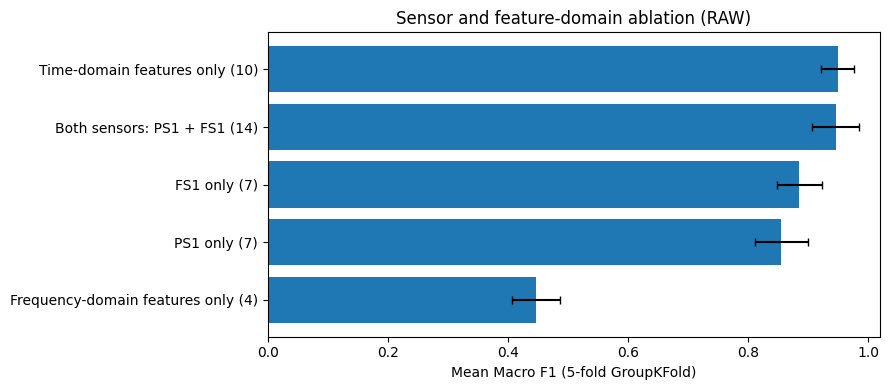

In [12]:
base_feat = features_by_mode['Raw']
time_suffixes = ('_mean', '_std', '_rms', '_p2p', '_diff_rms')
freq_suffixes = ('_spectral_centroid_Hz', '_power_frac_ge2Hz')
ablations = {
    'PS1 saja': [c for c in base_feat.columns if c.startswith('PS1_')],
    'FS1 saja': [c for c in base_feat.columns if c.startswith('FS1_')],
    'Dua sensor': list(base_feat.columns),
    'Fitur waktu saja': [c for c in base_feat.columns if c.endswith(time_suffixes)],
    'Fitur frekuensi saja': [c for c in base_feat.columns if c.endswith(freq_suffixes)],
}
assert all(len(v)>0 for v in ablations.values())
abl_rows=[]
for subset_name, cols in ablations.items():
    feat=base_feat[cols]
    for fold_id,(tr,te) in enumerate(cv_indices,1):
        abl_rows.append({'subset':subset_name, 'fold':fold_id,'n_fitur':len(cols),
                         **model_evaluate(feat,tr,te)})
ablation_results=pd.DataFrame(abl_rows)
ablation_summary=(ablation_results.groupby('subset')
                  .agg(macro_f1_mean=('macro_f1','mean'),macro_f1_sd=('macro_f1','std'),
                       balanced_accuracy_mean=('balanced_accuracy','mean'),n_fitur=('n_fitur','first'))
                  .sort_values('macro_f1_mean',ascending=False))
display(ablation_summary.round(4))
ablation_label_map = {
    'Fitur waktu saja': 'Time-domain features only (10)',
    'Dua sensor': 'Both sensors: PS1 + FS1 (14)',
    'FS1 saja': 'FS1 only (7)',
    'PS1 saja': 'PS1 only (7)',
    'Fitur frekuensi saja': 'Frequency-domain features only (4)',
}
fig,ax=plt.subplots(figsize=(9,4))
order=ablation_summary.index
plot_labels=[ablation_label_map.get(k, k) for k in order]
ax.barh(plot_labels,ablation_summary['macro_f1_mean'],xerr=ablation_summary['macro_f1_sd'],capsize=3)
ax.set(xlim=(0,1.02),xlabel='Mean Macro F1 (5-fold GroupKFold)',title='Sensor and feature-domain ablation (RAW)')
ax.invert_yaxis();plt.tight_layout();plt.show()

## E4c: Filter Window Sensitivity Analysis

We compare smoothing durations of **0.3, 0.5, and 1.0 s** across both sensors. A 0.1 s window is omitted because at `FS1`'s 10 Hz sampling rate it corresponds to a single sample (`L = 1`), performing no multi-sample averaging.

At each window duration, the IIR filter is matched to the **-3 dB cutoff frequency** of the corresponding FIR filter on each sensor. Results for the 0.5 s baseline window are reused directly from `E4a`. All configurations are evaluated on the exact same 5-fold splits. Because these window lengths are compared on the same validation folds without nested outer splitting, this sensitivity check is exploratory.

Filter parameters for 0.3 s and 1.0 s windows (see E2 table for 0.5 s):


,window_s,sensor,length_L,actual_window_s,cutoff_Hz,IIR_alpha
0,0.3,PS1,30,0.3,1.4786,0.9113
1,0.3,FS1,3,0.3,1.5529,0.4041
2,1.0,PS1,100,1.0,0.4440,0.9725
3,1.0,FS1,10,1.0,0.4449,0.7575


,window_s,mode,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,0.3,FIR,0.9477,0.0460,0.9480
1,0.3,IIR,0.9461,0.0369,0.9463
2,0.5,FIR,0.9454,0.0360,0.9456
3,0.5,IIR,0.9545,0.0323,0.9547
4,1.0,FIR,0.9504,0.0387,0.9506
5,1.0,IIR,0.9476,0.0400,0.9478


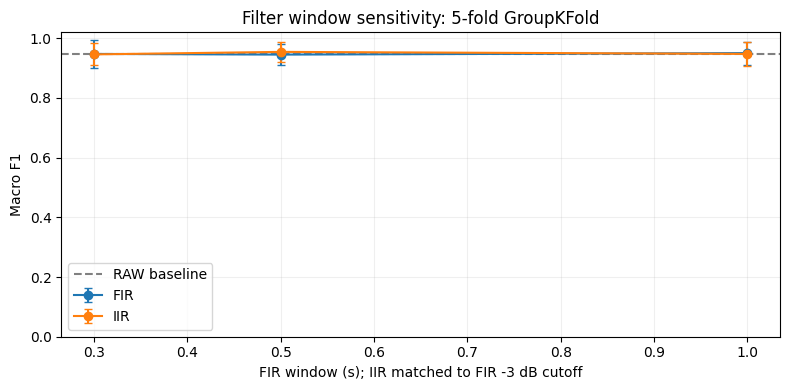

In [13]:
# Reuse the 0.5 s cross-validation scores already computed in E4a.
sensitivity_rows=[]
for _,r in cv_results.iterrows():
    if r['mode'] in ['FIR','IIR']:
        sensitivity_rows.append({'window_s':0.5,'fold':int(r['fold']),'mode':r['mode'],
                                 'macro_f1':r['macro_f1'],'balanced_accuracy':r['balanced_accuracy']})

sensitivity_filter_specs=[]
for window_s in [0.3, 1.0]:
    temp_filters={name:design_filters(fs,window_seconds=window_s)
                  for name,fs in sample_rates.items()}
    for sensor,cfg in temp_filters.items():
        sensitivity_filter_specs.append({'window_s':window_s,'sensor':sensor,
                                         'length_L':cfg['L'],'actual_window_s':cfg['L']/sample_rates[sensor],
                                         'cutoff_Hz':cfg['fc_Hz'],'IIR_alpha':cfg['alpha']})
    for mode in ['FIR','IIR']:
        feature_parts=[]
        for sensor in ['PS1','FS1']:
            b,a=temp_filters[sensor][mode]
            filtered=filter_cycles(signals[sensor][selected_idx],b,a)
            feature_parts.append(extract_cycle_features(filtered,sample_rates[sensor],sensor))
            del filtered
        feat=pd.concat(feature_parts,axis=1)
        assert list(feat.columns)==list(base_feat.columns)
        for fold_id,(tr,te) in enumerate(cv_indices,1):
            score=model_evaluate(feat,tr,te)
            sensitivity_rows.append({'window_s':window_s,'fold':fold_id,'mode':mode,
                                     'macro_f1':score['macro_f1'],
                                     'balanced_accuracy':score['balanced_accuracy']})
        del feat,feature_parts

sensitivity_results=pd.DataFrame(sensitivity_rows)
sensitivity_summary=(sensitivity_results.groupby(['window_s','mode'])
                     .agg(macro_f1_mean=('macro_f1','mean'),macro_f1_sd=('macro_f1','std'),
                          balanced_accuracy_mean=('balanced_accuracy','mean'))
                     .reset_index())
print('Filter parameters for 0.3 s and 1.0 s windows (see E2 table for 0.5 s):')
display(pd.DataFrame(sensitivity_filter_specs).round(4))
display(sensitivity_summary.round(4))
fig,ax=plt.subplots(figsize=(8,4))
for mode in ['FIR','IIR']:
    rr=sensitivity_summary[sensitivity_summary['mode']==mode].sort_values('window_s')
    ax.errorbar(rr['window_s'],rr['macro_f1_mean'],yerr=rr['macro_f1_sd'],marker='o',capsize=3,label=mode)
raw_mean=cv_results.loc[cv_results['mode']=='Raw','macro_f1'].mean()
ax.axhline(raw_mean,linestyle='--',color='gray',label='RAW baseline')
ax.set(xlabel='FIR window (s); IIR matched to FIR -3 dB cutoff',ylabel='Macro F1',title='Filter window sensitivity: 5-fold GroupKFold',ylim=(0,1.02))
ax.legend();ax.grid(alpha=0.2);plt.tight_layout();plt.show()

## E5 (Optional): Downsampling and Anti-Aliasing Simulation

Executed **only if** `RUN_E5 = True` in the initial configuration cell. `PS1` is downsampled from 100 Hz to 10 Hz using two methods:

1. Selecting every 10th sample without pre-filtering (*naive decimation*).
2. Polyphase resampling (`scipy.signal.resample_poly`), which applies a digital anti-aliasing low-pass filter prior to decimation.

This simulation illustrates how unsmoothed decimation can distort rapid fluctuations; it is **not a physical re-digitization of analog sensor hardware**.

In [14]:
if RUN_E5:
    original=ps1[example_cid].astype(np.float64)
    fs_old,fs_new=100,10
    naive=original[::10]
    aa=signal.resample_poly(original,up=1,down=10)
    time_new=np.arange(len(naive))/fs_new
    fig,axes=plt.subplots(2,1,figsize=(11,6))
    axes[0].plot(np.arange(len(original))/fs_old,original,label='Original PS1 (100 Hz)',lw=0.7)
    axes[0].scatter(time_new,naive,s=9,label='Naive decimation (10 Hz)')
    axes[0].set(xlabel='Time (s)',ylabel='bar',title='Sample decimation without anti-aliasing filter');axes[0].legend()
    axes[1].plot(time_new,naive,label='Naive 10 Hz',lw=1)
    axes[1].plot(time_new[:len(aa)],aa,label='Anti-alias + resample_poly',lw=1)
    axes[1].set(xlabel='Time (s)',ylabel='bar',title='Comparison of downsampling methods');axes[1].legend()
    plt.tight_layout();plt.show()
else:
    print('E5 skipped. Set RUN_E5=True in Cell 2 to run the downsampling illustration.')

E5 skipped. Set RUN_E5=True in Cell 2 to run the downsampling illustration.


## Exporting Core Evaluation Tables and Interpretation Guidelines

When `SAVE_RESULTS = True`, the core evaluation tables are saved to `results/`:
- `metrics_holdout.csv`: Exploratory single grouped train/test split metrics.
- `cv_5fold_per_fold.csv`, `cv_5fold_summary.csv`: Primary 5-fold `GroupKFold` validation metrics.
- `ablation_per_fold.csv`, `ablation_summary.csv`: Sensor and feature-domain ablation metrics on unfiltered signals.
- `sensitivity_per_fold.csv`, `sensitivity_summary.csv`: Filter window duration sensitivity metrics (`0.3 s`, `0.5 s`, `1.0 s`).
- `quality_check.csv`, `split_profile_holdout.csv`: Sensor integrity audit and holdout split assignments.

**Interpretation guideline:** Performance differences between Raw, FIR, and IIR apply specifically to this sensor pair, feature set, and grouped validation design. Smoother waveforms do not automatically yield better classifiers. When mean differences are small relative to fold-to-fold variation, conclusions should remain cautious.

In [15]:
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
    metrics_df.to_csv(OUTPUT_DIR/'metrics_holdout.csv')
    qc.to_csv(OUTPUT_DIR/'quality_check.csv',index=False)
    pd.DataFrame({'cycle_id':meta.cycle_id,'pump_leakage':y,'group':groups,
                  'split':np.where(np.isin(np.arange(len(meta)),train_idx),'train','test')}).to_csv(
                      OUTPUT_DIR/'split_profile_holdout.csv',index=False)
    cv_results.to_csv(OUTPUT_DIR/'cv_5fold_per_fold.csv',index=False)
    cv_summary.to_csv(OUTPUT_DIR/'cv_5fold_summary.csv')
    ablation_results.to_csv(OUTPUT_DIR/'ablation_per_fold.csv',index=False)
    ablation_summary.to_csv(OUTPUT_DIR/'ablation_summary.csv')
    sensitivity_results.to_csv(OUTPUT_DIR/'sensitivity_per_fold.csv',index=False)
    sensitivity_summary.to_csv(OUTPUT_DIR/'sensitivity_summary.csv',index=False)
    print('Core result tables saved to:',OUTPUT_DIR.name)
print('Core evaluation complete. Grouped cross-validation on a single laboratory test rig does not replace validation on unseen machines.')

Core result tables saved to: results
Core evaluation complete. Grouped cross-validation on a single laboratory test rig does not replace validation on unseen machines.


## E6: Extended Diagnostic Evaluation Using Pooled Out-of-Fold (OOF) Predictions

This section extends `E1` through `E5` without altering the dataset, extracted features, digital filters, or `GroupKFold` splits. Every one of the 1,449 stable cycles is predicted **exactly once** when its configuration group is held out as the test fold. No `cooler|valve|accumulator` combination is shared between training and test sets within any fold.

**Objective:** Rather than chasing higher aggregate accuracy, we inspect which leakage classes are confused and how many **severe pump leakage cases (class 2) are missed**. Fold-averaged Macro F1 scores alone do not show whether missed severe cycles are predicted as weak leakage (class 1) or normal operation (class 0).

> Note: `class 0/1/2` denotes internal pump leakage severity. The unit of analysis is a **60-second operating cycle**, not an individual time point. All OOF predictions come strictly from held-out test folds.

In [16]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.inspection import permutation_importance

N = len(y)
oof_rows = []
models_oof = {}
for mode in ['Raw', 'FIR', 'IIR']:
    pred = oof_preds_cache[mode]
    p_severe = oof_prob_cache[mode]
    fold_of = oof_fold_cache
    assert np.all(pred >= 0) and np.all(fold_of > 0) and np.isfinite(p_severe).all()
    assert sorted(np.unique(fold_of).tolist()) == list(range(1, CV_FOLDS+1))
    models_oof[mode] = pred
    oof_rows.append(pd.DataFrame({
        'cycle_id': meta['cycle_id'].to_numpy(), 'fold': fold_of, 'mode': mode,
        'group': groups, 'true_label': y, 'pred_label': pred,
        'prob_class_2': p_severe,
        'severity_abs_error': np.abs(y-pred),
    }))
oof_predictions = pd.concat(oof_rows, ignore_index=True)
assert len(oof_predictions) == N * 3
print('Total OOF prediction rows:', len(oof_predictions), '| unique stable cycles:', N)
display(oof_predictions.head())

Total OOF prediction rows: 4347 | unique stable cycles: 1449


,cycle_id,fold,mode,group,true_label,pred_label,prob_class_2,severity_abs_error
0,211,1,Raw,3|73|130,2,2,0.869331,0
1,212,1,Raw,3|73|130,2,1,0.106825,1
2,213,1,Raw,3|73|130,2,1,0.061913,1
3,214,1,Raw,3|73|130,2,1,0.445513,1
4,215,1,Raw,3|73|130,2,1,0.386610,1


## E7: Per-Class Metrics and Critical Diagnostic Errors

Metrics evaluated on the pooled out-of-fold predictions (`n = 1,449` stable cycles):

- **Pooled Macro F1:** Unweighted average F1 score across all three classes computed on the pooled OOF confusion matrix.
- **Class 2 recall:** Proportion of actual severe leakage cycles (`n = 480`) correctly classified as class 2.
- **Class 2 precision:** Proportion of predicted severe leakage cycles that are genuinely class 2.
- **Class 2 miss rate:** Fraction of actual severe leakage cycles misclassified as class 0 or class 1.
- **Severe-as-normal errors (`2 -> 0`):** Actual severe leakage cycles misclassified as normal operation (class 0).
- **Ordinal MAE:** Mean absolute distance between true and predicted integer class labels, `abs(y_true - y_pred)`, which penalizes a two-step error (`2 -> 0`) more heavily than a one-step error (`2 -> 1`) without assuming monetary costs.

Each confusion matrix below aggregates out-of-fold test predictions across all five folds.

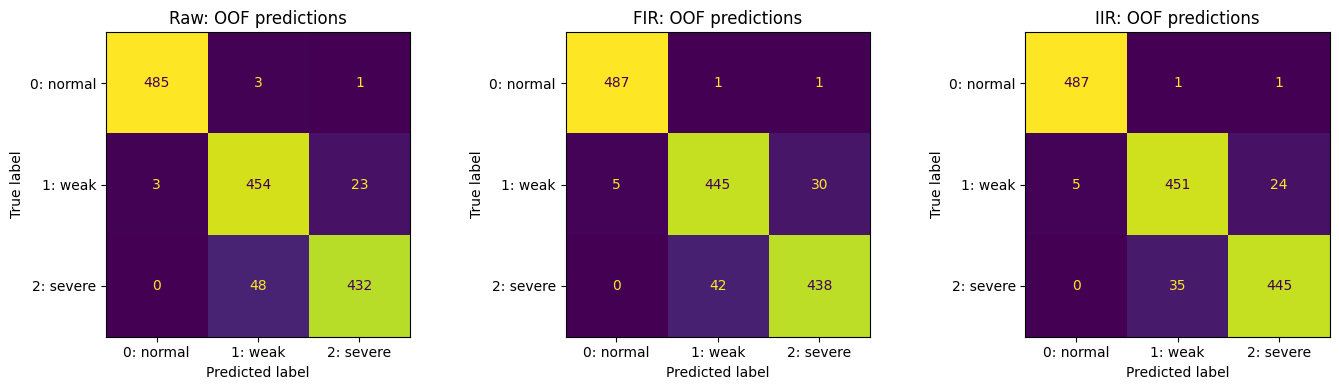

PER-CLASS METRICS (pooled OOF across all 1,449 stable cycles):


,mode,label,precision,recall,f1,support
0,Raw,0,0.9939,0.9918,0.9928,489
1,Raw,1,0.8990,0.9458,0.9218,480
2,Raw,2,0.9474,0.9000,0.9231,480
3,FIR,0,0.9898,0.9959,0.9929,489
4,FIR,1,0.9119,0.9271,0.9194,480
5,FIR,2,0.9339,0.9125,0.9231,480
6,IIR,0,0.9898,0.9959,0.9929,489
7,IIR,1,0.9261,0.9396,0.9328,480
8,IIR,2,0.9468,0.9271,0.9368,480


CRITICAL DIAGNOSTIC ERRORS AND ORDINAL SEVERITY ERROR:


,mode,total_severe,severe_pred_normal,severe_pred_mild,severe_detected,severe_miss_rate,ordinal_mae,pooled_macro_f1
0,Raw,480,0,48,432,0.1000,0.0545,0.9459
1,FIR,480,0,42,438,0.0875,0.0552,0.9451
2,IIR,480,0,35,445,0.0729,0.0462,0.9542


Note: Pooled OOF Macro F1 is computed over all 1,449 predictions and differs slightly from the unweighted 5-fold mean Macro F1.


In [17]:
perclass_rows, critical_rows = [], []
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, mode in zip(axs, ['Raw', 'FIR', 'IIR']):
    pred = models_oof[mode]
    mat = confusion_matrix(y, pred, labels=classes)
    ConfusionMatrixDisplay(mat, display_labels=['0: normal','1: weak','2: severe']).plot(
        ax=ax, colorbar=False, values_format='d'
    )
    ax.set_title(f'{mode}: OOF predictions')
    prec, rec, f1s, support = precision_recall_fscore_support(
        y, pred, labels=classes, zero_division=0
    )
    for i, cls in enumerate(classes):
        perclass_rows.append(dict(mode=mode, label=int(cls), precision=prec[i],
                                  recall=rec[i], f1=f1s[i], support=int(support[i])))
    critical_rows.append(dict(
        mode=mode, total_severe=int(mat[2].sum()),
        severe_pred_normal=int(mat[2, 0]), severe_pred_mild=int(mat[2, 1]),
        severe_detected=int(mat[2, 2]),
        severe_miss_rate=float((mat[2,0]+mat[2,1]) / mat[2].sum()),
        ordinal_mae=float(np.abs(y-pred).mean()),
        pooled_macro_f1=float(f1_score(y, pred, average='macro'))
    ))
plt.tight_layout(); plt.show()
perclass_metrics = pd.DataFrame(perclass_rows)
critical_errors = pd.DataFrame(critical_rows)
print('PER-CLASS METRICS (pooled OOF across all 1,449 stable cycles):')
display(perclass_metrics.round(4))
print('CRITICAL DIAGNOSTIC ERRORS AND ORDINAL SEVERITY ERROR:')
display(critical_errors.round(4))
print('Note: Pooled OOF Macro F1 is computed over all 1,449 predictions and differs slightly from the unweighted 5-fold mean Macro F1.')

## E8: Hypothetical Cost-Sensitive Error Evaluation

Pump leakage severity is ordinal (`0`, `1`, `2`). Misclassifying severe leakage as normal (`2 -> 0`) or weak (`2 -> 1`) typically carries higher operational risk than a false alarm, but **the UCI dataset does not provide industrial maintenance or downtime costs**. We therefore evaluate **three hypothetical penalty matrices** and report the *mean relative cost index per 100 cycles* rather than monetary values.

Matrix rows represent **true classes** (`0`, `1`, `2`) and columns represent **predicted classes** (`0`, `1`, `2`), with zero penalty on the diagonal. All three signal representations are evaluated on the **exact same pooled OOF predictions** without post-hoc threshold tuning:

- **Ordinal distance:** \(|y - \hat{y}|\) (one-step error = 1, two-step error = 2).
- **Moderate safety-first (`Safety-first sedang`):** Assigns higher penalties when severe leakage is under-predicted as weak (`4`) or normal (`8`).
- **High safety-first (`Safety-first tinggi`):** Increases the penalty for under-predicting severe leakage (`6` for `2 -> 1`, `12` for `2 -> 0`).

Any interpretation of these indices must explicitly reference the assumed penalty weights.

Ordinal distance | rows = actual class, columns = predicted class


,pred 0,pred 1,pred 2
actual 0,0.0,1.0,2.0
actual 1,1.0,0.0,1.0
actual 2,2.0,1.0,0.0


Safety-first sedang | rows = actual class, columns = predicted class


,pred 0,pred 1,pred 2
actual 0,0.0,1.0,3.0
actual 1,2.0,0.0,2.0
actual 2,8.0,4.0,0.0


Safety-first tinggi | rows = actual class, columns = predicted class


,pred 0,pred 1,pred 2
actual 0,0.0,2.0,5.0
actual 1,3.0,0.0,2.0
actual 2,12.0,6.0,0.0


HYPOTHETICAL MISCLASSIFICATION COST INDEX (LOWER IS BETTER):


mode,FIR,IIR,Raw
scenario,,,
Ordinal distance,5.52,4.62,5.45
Safety-first sedang,16.70,13.94,17.25
Safety-first tinggi,23.05,19.32,24.43


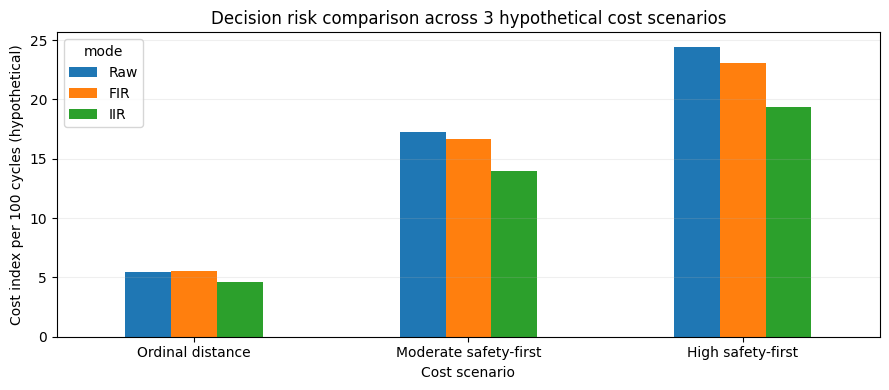

In [18]:
cost_scenarios = {
    'Ordinal distance': np.array([[0, 1, 2], [1, 0, 1], [2, 1, 0]], dtype=float),
    'Safety-first sedang': np.array([[0, 1, 3], [2, 0, 2], [8, 4, 0]], dtype=float),
    'Safety-first tinggi': np.array([[0, 2, 5], [3, 0, 2], [12, 6, 0]], dtype=float),
}
cost_rows = []
for scenario, matrix in cost_scenarios.items():
    print(scenario, '| rows = actual class, columns = predicted class')
    display(pd.DataFrame(matrix, index=['actual 0','actual 1','actual 2'],
                         columns=['pred 0','pred 1','pred 2']))
    for mode in ['Raw', 'FIR', 'IIR']:
        pred = models_oof[mode]
        costs = matrix[y, pred]
        cost_rows.append({'scenario':scenario,'mode':mode,
                          'mean_cost_index':float(costs.mean()),
                          'cost_per_100_cycles':float(costs.mean()*100)})
cost_results = pd.DataFrame(cost_rows)
print('HYPOTHETICAL MISCLASSIFICATION COST INDEX (LOWER IS BETTER):')
display(cost_results.pivot(index='scenario', columns='mode',
                           values='cost_per_100_cycles').round(2))
scenario_label_map = {
    'Ordinal distance': 'Ordinal distance',
    'Safety-first sedang': 'Moderate safety-first',
    'Safety-first tinggi': 'High safety-first',
}
fig,ax=plt.subplots(figsize=(9,4))
ct = cost_results.pivot(index='scenario',columns='mode',values='cost_per_100_cycles')
ct[['Raw','FIR','IIR']].rename(index=scenario_label_map).plot(kind='bar',ax=ax,rot=0)
ax.set(xlabel='Cost scenario', ylabel='Cost index per 100 cycles (hypothetical)',
       title='Decision risk comparison across 3 hypothetical cost scenarios')
ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()

## E9: Optional Feature Contribution Check via Permutation Importance

To inspect which individual features influence predictions on the locked grouped holdout split from `E4`, permutation importance can be computed on the held-out test cycles. Permutation importance reflects **predictive reliance within the fitted model** rather than physical causality, and correlated features can share importance scores.

This step is disabled by default (`RUN_PERMUTATION_IMPORTANCE = False`) to keep standard execution fast. When enabled, it compares `Raw` and `IIR` across the same 14 features. Statistical importance to a tree ensemble does not establish the physical mechanics of internal pump wear.

In [19]:
RUN_PERMUTATION_IMPORTANCE = False  # Set True to run permutation importance on the grouped holdout split
importance_rows = []
if RUN_PERMUTATION_IMPORTANCE:
    for mode in ['Raw','IIR']:
        X=features_by_mode[mode]
        clf_imp=RandomForestClassifier(
            n_estimators=CV_TREES,min_samples_leaf=2,
            class_weight='balanced_subsample',random_state=SEED,n_jobs=-1)
        clf_imp.fit(X.iloc[train_idx],y[train_idx])
        result=permutation_importance(
            clf_imp, X.iloc[test_idx], y[test_idx], scoring='f1_macro',
            n_repeats=5, random_state=SEED,n_jobs=1)
        for idx,name in enumerate(X.columns):
            importance_rows.append({'mode':mode,'feature':name,
                'f1_drop_mean':float(result.importances_mean[idx]),
                'f1_drop_sd':float(result.importances_std[idx])})
    importance_results=pd.DataFrame(importance_rows)
    for mode in ['Raw','IIR']:
        top=(importance_results[importance_results['mode']==mode]
             .sort_values('f1_drop_mean',ascending=False).head(10))
        print('Top 10 features:',mode)
        display(top.round(5))
        fig,ax=plt.subplots(figsize=(9,4))
        ax.barh(top.feature[::-1],top.f1_drop_mean[::-1],xerr=top.f1_drop_sd[::-1],capsize=2)
        ax.set(xlabel='Mean Macro F1 drop after feature permutation',
               title=f'Permutation importance: {mode} (grouped holdout)')
        plt.tight_layout();plt.show()
else:
    print('Permutation importance skipped. Set RUN_PERMUTATION_IMPORTANCE=True to compute.')
importance_results = pd.DataFrame(importance_rows, columns=['mode','feature','f1_drop_mean','f1_drop_sd'])

Permutation importance skipped. Set RUN_PERMUTATION_IMPORTANCE=True to compute.


## E10: Supported Conclusions and Methodological Limitations

**Findings supported by the experiments:**

1. `Raw`, `FIR`, and `IIR` representations were evaluated on identical `GroupKFold` splits. Pooling out-of-fold predictions separates severe-as-normal (`2 -> 0`, zero cases across all modes) from severe-as-weak (`2 -> 1`, reduced from 48 in Raw to 42 in FIR and 35 in IIR) misclassifications.
2. Method rankings depend on the evaluation lens: IIR achieved the highest 5-fold mean Macro F1 (`0.9545` vs. `0.9462` for Raw) and highest pooled severe recall (`92.71%` vs. `90.00%`), whereas Raw had slightly higher severe-class precision (`94.74%` vs. `94.68%`), outperformed IIR in Fold 3 and on the single holdout split, and reached `0.9492` mean Macro F1 when restricted to its 10 time-domain features.
3. The 0.83 percentage point mean Macro F1 difference between IIR and Raw is smaller than the fold-to-fold standard deviation (`3.23` to `3.94` percentage points) and is not claimed to be statistically significant or generalizable to other machines.
4. Feature ablation and importance results describe model behavior on this 14-feature design rather than proving physical failure mechanisms.

**Key methodological limitations:** All recordings originate from a single laboratory test rig; the unit of observation is a complete 60-second cycle (`stable_flag = 0`); grouping by `(cooler, valve, accumulator)` states controls for auxiliary operating regimes on the same rig rather than cross-machine transfer; cost matrices are hypothetical; the five cross-validation folds share overlapping training data; and comparing multiple smoothing windows (`0.3 s`, `0.5 s`, `1.0 s`) on the same validation folds is exploratory.

In [20]:
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    oof_predictions.to_csv(OUTPUT_DIR/'dsa_oof_predictions.csv',index=False)
    perclass_metrics.to_csv(OUTPUT_DIR/'dsa_perclass_metrics.csv',index=False)
    critical_errors.to_csv(OUTPUT_DIR/'dsa_critical_errors.csv',index=False)
    cost_results.to_csv(OUTPUT_DIR/'dsa_cost_scenarios.csv',index=False)
    if not importance_results.empty:
        importance_results.to_csv(OUTPUT_DIR/'dsa_permutation_importance.csv',index=False)
    print('DSA evaluation tables saved to:',OUTPUT_DIR.name)
    print('Exported files: dsa_oof_predictions.csv, dsa_perclass_metrics.csv, dsa_critical_errors.csv, dsa_cost_scenarios.csv')
print('COMPLETED: Review Section E10 for supported conclusions and methodological limitations.')

DSA evaluation tables saved to: results
Exported files: dsa_oof_predictions.csv, dsa_perclass_metrics.csv, dsa_critical_errors.csv, dsa_cost_scenarios.csv
COMPLETED: Review Section E10 for supported conclusions and methodological limitations.


## References and Scope Notes

**Dataset and Primary Literature**
1. Helwig, N., Pignanelli, E., & Schütze, A. (2015). *Condition Monitoring of Hydraulic Systems* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CW21
2. Helwig, N., Pignanelli, E., & Schütze, A. (2015). *Condition Monitoring of a Complex Hydraulic System Using Multivariate Statistics*. Proceedings of the 2015 IEEE International Instrumentation and Measurement Technology Conference (I2MTC), pp. 210-215. https://doi.org/10.1109/I2MTC.2015.7151267
3. Helwig, N., & Schütze, A. (2015). *Detecting and compensating sensor faults in a hydraulic condition monitoring system*. Proceedings of SENSOR 2015, pp. 641-646. https://doi.org/10.5162/sensor2015/D8.1
4. Schneider, T., Helwig, N., & Schütze, A. (2017). *Automatic feature extraction and selection for classification of cyclical time series data*. tm - Technisches Messen, 84(3), 198-206. https://doi.org/10.1515/teme-2016-0072

**Software Documentation**
5. SciPy Signal Processing: [lfilter](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lfilter.html), [lfilter_zi](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lfilter_zi.html), [freqz](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.freqz.html), [welch](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html), [resample_poly](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html).
6. scikit-learn: [GroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html), [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [f1_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).

**Summary of Reporting Constraints:** All measurements come from a single laboratory test rig; feature correlations do not establish physical causality; grouping by auxiliary component states does not test generalization across different machines; window sensitivity comparisons across folds are exploratory; and target labels are annotated per 60-second cycle rather than per time sample.